# 05. Xây dựng mô hình và đánh giá trên tập dev (Modeling + Evaluation)

**Chỉ dùng tập dev (80%)**, chia 5 fold theo thương hiệu (notebook 04). Tập test 20% không dùng ở đây; nó chỉ được mở một lần ở notebook 06, sau khi đã chốt mô hình ở đây.

| Mục | Nội dung |
|---|---|
| 7.1 | Hai đường cơ sở: đoán hạng phổ biến nhất; đoán theo nhóm `pnns_groups_2` |
| 7.2–7.5 | Logistic Regression, Decision Tree, Random Forest, LightGBM (mỗi loại thử vài tham số) |
| 7.6 | Tinh chỉnh LightGBM bằng Optuna |
| 7.7 | So sánh, chọn mô hình tốt nhất |
| 8.1–8.5 | Đánh giá mô hình tốt nhất: từng hạng, ma trận nhầm lẫn, ROC-AUC, theo quốc gia, nhóm khó; ablation; đặc trưng quan trọng; trả lời 3 câu hỏi nghiên cứu |
| 8.6 | Lưu mô hình và dự đoán |

**Đánh giá chéo (cross-validation):** với mỗi fold k = 0..4, tạo một mô hình **mới**, học trên 4 fold còn lại, dự đoán fold k. Vì pipeline đặc trưng nằm trong mô hình, phần "học" của đặc trưng cũng chỉ thấy 4 fold đó. Kết quả là trung bình ± độ lệch chuẩn qua 5 fold.

Thời gian chạy cả notebook khoảng 30–40 phút (phần lâu nhất là 7.6 và 8.4).

In [1]:
# Chạy từ thư mục gốc dự án để đọc được data/, sql/ và import src/
import os, sys
from pathlib import Path
root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(root)
sys.path.insert(0, str(root))

import numpy as np
import pandas as pd
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
GRADE_COLORS = {"a": "#038141", "b": "#85BB2F", "c": "#FECB02", "d": "#EE8100", "e": "#E63E11"}
FIG_DIR = Path("reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

import time
from src.modeling import GRADES, cross_validate, make_model, metrics, select_dev, summarize
from src.features import GROUPS, feature_names

X = pd.read_parquet("data/final/clean_features.parquet")
y = pd.read_parquet("data/final/clean_labels.parquet")["nutriscore_grade"]
split = pd.read_parquet("data/final/split.parquet")
X_dev, y_dev, split_dev = select_dev(X, y, split)          # KHÔNG dùng tập test
folds = split_dev["fold"].to_numpy()
print("Dev:", X_dev.shape, "| số dòng mỗi fold:", np.bincount(folds))

Dev: (23922, 27) | số dòng mỗi fold: [4783 4783 4786 4787 4783]


In [2]:
results, oof, factories = {}, {}, {}
SHOW = ["macro_f1", "accuracy", "precision", "recall", "qwk", "within_one", "roc_auc"]

def run(name, make):
    '''Đánh giá chéo 5 fold một mô hình, lưu kết quả để so sánh.'''
    start = time.time()
    per_fold, pred, proba = cross_validate(make, X_dev, y_dev, folds)
    results[name], oof[name], factories[name] = per_fold, (pred, proba), make
    print(f"{name}: Macro-F1 {per_fold['macro_f1'].mean():.3f} ± {per_fold['macro_f1'].std():.3f}  ({time.time() - start:.0f} giây)")
    return per_fold

## 7.1. Đường cơ sở (baseline)
- **Hạng phổ biến nhất:** luôn đoán E. Macro-F1 rất thấp: cho thấy vì sao không dùng accuracy làm chỉ số chính.
- **Theo nhóm danh mục:** đoán hạng phổ biến nhất của nhóm `pnns_groups_2` trong phần huấn luyện. Đây là mốc phải vượt (tiêu chí thành công ở notebook 01).

In [3]:
run("Đường cơ sở: hạng phổ biến nhất", lambda: make_model("majority"))
run("Đường cơ sở: theo pnns_groups_2", lambda: make_model("category"))
pd.DataFrame({n: summarize(r)[SHOW] for n, r in results.items()}).T

Đường cơ sở: hạng phổ biến nhất: Macro-F1 0.088 ± 0.000  (0 giây)


Đường cơ sở: theo pnns_groups_2: Macro-F1 0.412 ± 0.004  (0 giây)


,macro_f1,accuracy,precision,recall,qwk,within_one,roc_auc
Đường cơ sở: hạng phổ biến nhất,0.088 ± 0.0,0.284 ± 0.0,0.057 ± 0.0,0.2 ± 0.0,0.0 ± 0.0,0.522 ± 0.0,0.5 ± 0.0
Đường cơ sở: theo pnns_groups_2,0.412 ± 0.004,0.462 ± 0.003,0.456 ± 0.008,0.42 ± 0.004,0.463 ± 0.012,0.734 ± 0.003,0.753 ± 0.005


## 7.2. Logistic Regression
Mô hình tuyến tính: mỗi đặc trưng có một trọng số cho từng hạng. `C` nhỏ = phạt trọng số mạnh hơn (chống quá khớp). `class_weight="balanced"` tăng trọng số cho hạng ít mẫu (B). Biến số đã được chuẩn hóa (StandardScaler) nên các trọng số so được với nhau.

In [4]:
grid = {}
for C in (0.03, 0.1, 0.3, 1.0):
    grid[C] = cross_validate(lambda: make_model("logreg", C=C), X_dev, y_dev, folds)[0]["macro_f1"].mean()
print({c: round(v, 3) for c, v in grid.items()})
best_C = max(grid, key=grid.get)
run(f"Logistic Regression (C={best_C})", lambda: make_model("logreg", C=best_C));

{0.03: np.float64(0.56), 0.1: np.float64(0.562), 0.3: np.float64(0.562), 1.0: np.float64(0.56)}


Logistic Regression (C=0.1): Macro-F1 0.562 ± 0.011  (13 giây)


## 7.3. Decision Tree
Cây chia dữ liệu bằng các câu hỏi có/không ("có thẻ `en:sugar`?"). Cây càng sâu càng khớp dữ liệu huấn luyện, dễ quá khớp. Thử các độ sâu khác nhau, `min_samples_leaf=20` để lá không quá nhỏ.

In [5]:
grid = {}
for depth in (4, 8, 12, 16):
    grid[depth] = cross_validate(lambda: make_model("tree", max_depth=depth, min_samples_leaf=20),
                                 X_dev, y_dev, folds)[0]["macro_f1"].mean()
print({d: round(v, 3) for d, v in grid.items()})
best_depth = max(grid, key=grid.get)
run(f"Decision Tree (sâu {best_depth})", lambda: make_model("tree", max_depth=best_depth, min_samples_leaf=20));

{4: np.float64(0.377), 8: np.float64(0.485), 12: np.float64(0.509), 16: np.float64(0.516)}


Decision Tree (sâu 16): Macro-F1 0.516 ± 0.008  (15 giây)


In [6]:
# Một cây nông (sâu 3) học trên toàn bộ dev, chỉ để NHÌN xem cây đặt câu hỏi gì
from sklearn.tree import export_text
small = make_model("tree", max_depth=3).fit(X_dev, y_dev)
print(export_text(small["model"], feature_names=feature_names(small["features"]), class_names=GRADES))

|--- position__pos_sugar <= 0.51
|   |--- nova__nova_1 <= 0.50
|   |   |--- pnns__pnns_groups_2_cheese <= 0.50
|   |   |   |--- class: b
|   |   |--- pnns__pnns_groups_2_cheese >  0.50
|   |   |   |--- class: d
|   |--- nova__nova_1 >  0.50
|   |   |--- pnns__pnns_groups_1_beverages <= 0.50
|   |   |   |--- class: a
|   |   |--- pnns__pnns_groups_1_beverages >  0.50
|   |   |   |--- class: b
|--- position__pos_sugar >  0.51
|   |--- categories__en:sweet-snacks <= 0.50
|   |   |--- position__pos_sugar <= 0.98
|   |   |   |--- class: c
|   |   |--- position__pos_sugar >  0.98
|   |   |   |--- class: e
|   |--- categories__en:sweet-snacks >  0.50
|   |   |--- ingredients__en:cocoa <= 0.50
|   |   |   |--- class: e
|   |   |--- ingredients__en:cocoa >  0.50
|   |   |   |--- class: e



## 7.4. Random Forest
Nhiều cây sâu, mỗi cây học trên một mẫu bootstrap và chỉ xét một phần đặc trưng ở mỗi lần chia; dự đoán = bỏ phiếu. Trung bình nhiều cây làm giảm phương sai so với một cây.

In [7]:
run("Random Forest (300 cây)", lambda: make_model("forest", n_estimators=300, min_samples_leaf=2));

Random Forest (300 cây): Macro-F1 0.606 ± 0.008  (49 giây)


## 7.5. LightGBM (gradient boosting), tham số mặc định
Các cây được xây **lần lượt**, cây sau sửa lỗi của các cây trước. Thường mạnh nhất với dữ liệu dạng bảng, chạy nhanh trên ma trận thưa.

In [8]:
run("LightGBM (mặc định)", lambda: make_model("lgbm"));

LightGBM (mặc định): Macro-F1 0.599 ± 0.007  (15 giây)


## 7.6. Tinh chỉnh LightGBM bằng Optuna
Optuna thử 30 bộ tham số. Mỗi lần thử, nó dựa vào kết quả các lần trước để chọn vùng tham số hứa hẹn hơn (thuật toán TPE, seed 42). Lần thử đầu tiên là tham số mặc định, nên kết quả không thể tệ hơn 7.5. Lần thử nào kém hơn trung vị ngay sau vài fold đầu thì bị **cắt sớm** (MedianPruner) để tiết kiệm thời gian.

Để nhanh hơn: đặc trưng không phụ thuộc tham số LightGBM, nên ma trận đặc trưng của từng fold được tính **một lần** rồi dùng lại cho mọi lần thử. Pipeline vẫn chỉ fit trên phần huấn luyện của fold đó.

Lưu ý: tham số được chọn bằng chính 5 fold này nên Macro-F1 sau tinh chỉnh **hơi lạc quan**. Con số khách quan là kết quả trên tập test.

In [9]:
import optuna
from lightgbm import LGBMClassifier
from sklearn.metrics import f1_score
from src.features import make_features

fold_data = []
for k in range(5):
    tr, va = folds != k, folds == k
    feat = make_features().fit(X_dev[tr])
    fold_data.append((feat.transform(X_dev[tr]), y_dev[tr], feat.transform(X_dev[va]), y_dev[va]))

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 600, step=50),
        "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.2, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 15, 255, log=True),
        "min_child_samples": trial.suggest_int("min_child_samples", 3, 100, log=True),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.2, 1.0),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
    }
    scores = []
    for k, (X_tr, y_tr, X_va, y_va) in enumerate(fold_data):
        clf = LGBMClassifier(class_weight="balanced", subsample_freq=1, random_state=42, verbose=-1, **params)
        scores.append(f1_score(y_va, clf.fit(X_tr, y_tr).predict(X_va), average="macro"))
        trial.report(np.mean(scores), k)
        if trial.should_prune():
            raise optuna.TrialPruned()
    return np.mean(scores)

optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42),
                            pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=1))
study.enqueue_trial({"n_estimators": 100, "learning_rate": 0.1, "num_leaves": 31, "min_child_samples": 20,
                     "colsample_bytree": 1.0, "subsample": 1.0, "reg_lambda": 1e-3})   # = tham số mặc định
start = time.time()
study.optimize(objective, n_trials=30)
pruned = sum(t.state == optuna.trial.TrialState.PRUNED for t in study.trials)
print(f"{len(study.trials)} lần thử ({pruned} bị cắt sớm), {(time.time() - start) / 60:.1f} phút")
print("Tốt nhất: lần thử", study.best_trial.number, "| Macro-F1", round(study.best_value, 4))
best_params = {**study.best_params, "subsample_freq": 1}
best_params

30 lần thử (7 bị cắt sớm), 28.3 phút
Tốt nhất: lần thử 21 | Macro-F1 0.6249


{'n_estimators': 450,
 'learning_rate': 0.023696519795929575,
 'num_leaves': 187,
 'min_child_samples': 3,
 'colsample_bytree': 0.6453950698667689,
 'subsample': 0.9244648639872316,
 'reg_lambda': 1.726268877888677,
 'subsample_freq': 1}

In [10]:
# 5 lần thử tốt nhất: các tham số tốt có giống nhau không?
trials = study.trials_dataframe(attrs=("number", "value", "params", "state"))
trials[trials["state"] == "COMPLETE"].sort_values("value", ascending=False).head(5).round(4)

,number,value,params_colsample_bytree,params_learning_rate,params_min_child_samples,params_n_estimators,params_num_leaves,params_reg_lambda,params_subsample,state
21,21,0.6249,0.6454,0.0237,3,450,187,1.7263,0.9245,COMPLETE
28,28,0.6249,0.6802,0.0210,3,450,214,0.2594,0.9210,COMPLETE
23,23,0.6236,0.5862,0.0272,10,500,120,2.0254,0.9257,COMPLETE
29,29,0.6235,0.7751,0.0254,3,550,178,0.2266,0.9562,COMPLETE
22,22,0.6231,0.5905,0.0310,5,450,116,1.6180,0.9712,COMPLETE


In [11]:
# Đánh giá lại bộ tham số tốt nhất bằng đúng hàm cross_validate như các mô hình khác
run("LightGBM (Optuna)", lambda: make_model("lgbm", **best_params));

LightGBM (Optuna): Macro-F1 0.625 ± 0.007  (67 giây)


## 7.7. So sánh các mô hình

In [12]:
table = pd.DataFrame({n: summarize(r)[SHOW] for n, r in results.items()}).T
table

,macro_f1,accuracy,precision,recall,qwk,within_one,roc_auc
Đường cơ sở: hạng phổ biến nhất,0.088 ± 0.0,0.284 ± 0.0,0.057 ± 0.0,0.2 ± 0.0,0.0 ± 0.0,0.522 ± 0.0,0.5 ± 0.0
Đường cơ sở: theo pnns_groups_2,0.412 ± 0.004,0.462 ± 0.003,0.456 ± 0.008,0.42 ± 0.004,0.463 ± 0.012,0.734 ± 0.003,0.753 ± 0.005
Logistic Regression (C=0.1),0.562 ± 0.011,0.579 ± 0.01,0.559 ± 0.009,0.574 ± 0.009,0.711 ± 0.015,0.858 ± 0.007,0.856 ± 0.004
Decision Tree (sâu 16),0.516 ± 0.008,0.53 ± 0.005,0.516 ± 0.01,0.528 ± 0.006,0.641 ± 0.027,0.826 ± 0.023,0.819 ± 0.004
Random Forest (300 cây),0.606 ± 0.008,0.624 ± 0.006,0.604 ± 0.008,0.609 ± 0.008,0.74 ± 0.015,0.878 ± 0.008,0.877 ± 0.003
LightGBM (mặc định),0.599 ± 0.007,0.617 ± 0.005,0.595 ± 0.007,0.606 ± 0.008,0.742 ± 0.016,0.879 ± 0.008,0.877 ± 0.003
LightGBM (Optuna),0.625 ± 0.007,0.643 ± 0.005,0.627 ± 0.008,0.623 ± 0.006,0.768 ± 0.014,0.894 ± 0.007,0.887 ± 0.003


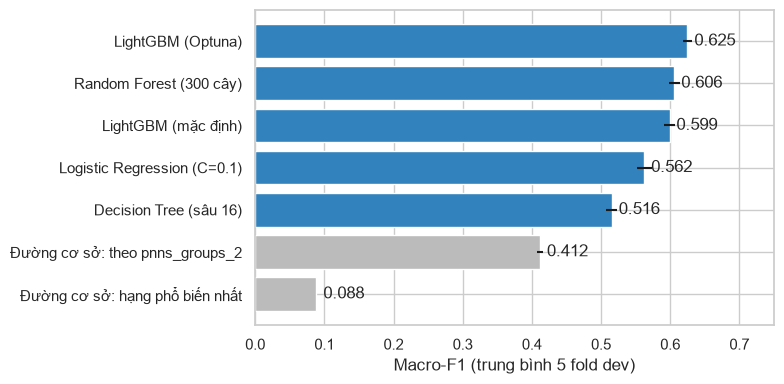

Mô hình tốt nhất: LightGBM (Optuna)
Macro-F1 0.625 vs đường cơ sở 0.412 | QWK 0.768 vs 0.463
Vượt đường cơ sở trên cả hai chỉ số: True


In [13]:
mean = pd.Series({n: r["macro_f1"].mean() for n, r in results.items()}).sort_values()
std = pd.Series({n: r["macro_f1"].std() for n, r in results.items()})[mean.index]
plt.figure(figsize=(8, 4))
plt.barh(mean.index, mean, xerr=std, color=["#bbbbbb" if "cơ sở" in n else "#3182bd" for n in mean.index])
for i, v in enumerate(mean):
    plt.text(v + 0.01, i, f"{v:.3f}", va="center")
plt.xlabel("Macro-F1 (trung bình 5 fold dev)"); plt.xlim(0, 0.75)
plt.tight_layout(); plt.savefig(FIG_DIR / "model_01_so_sanh.png", dpi=110); plt.show()

best_name = mean.index[-1]
baseline = results["Đường cơ sở: theo pnns_groups_2"].mean()
best = results[best_name].mean()
print("Mô hình tốt nhất:", best_name)
print(f"Macro-F1 {best['macro_f1']:.3f} vs đường cơ sở {baseline['macro_f1']:.3f} | QWK {best['qwk']:.3f} vs {baseline['qwk']:.3f}")
print("Vượt đường cơ sở trên cả hai chỉ số:", best["macro_f1"] > baseline["macro_f1"] and best["qwk"] > baseline["qwk"])

Nhận xét:
- Mọi mô hình học máy đều vượt xa hai đường cơ sở. Đường cơ sở "đa số" có accuracy 28% nhưng Macro-F1 chỉ 0,09: accuracy dễ đánh lừa khi lệch lớp.
- Cây quyết định đơn kém nhất, kể cả khi cho sâu 16 tầng (một cây không đủ để kết hợp hàng trăm thẻ). Random Forest và LightGBM mặc định tốt hơn nhiều. LightGBM sau tinh chỉnh tốt nhất.
- Chênh giữa các fold (độ lệch chuẩn) nhỏ, khoảng 0,01, nên thứ hạng giữa các mô hình là đáng tin.

## 8.1. Đánh giá mô hình tốt nhất: từng hạng, ma trận nhầm lẫn, ROC-AUC
Dùng **dự đoán ngoài fold** (mỗi sản phẩm dev được dự đoán bởi mô hình không thấy nó lúc học).

In [14]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

pred, proba = oof[best_name]
print(classification_report(y_dev, pred, labels=GRADES, digits=3))
auc = {g: roc_auc_score(y_dev == g, proba[:, i]) for i, g in enumerate(GRADES)}
print("ROC-AUC từng hạng (một-với-phần-còn-lại):", {g: round(v, 3) for g, v in auc.items()})

              precision    recall  f1-score   support

           a      0.710     0.711     0.711      3614
           b      0.507     0.466     0.485      2637
           c      0.575     0.581     0.578      5185
           d      0.593     0.594     0.593      5689
           e      0.750     0.766     0.758      6797

    accuracy                          0.643     23922
   macro avg      0.627     0.623     0.625     23922
weighted avg      0.642     0.643     0.642     23922

ROC-AUC từng hạng (một-với-phần-còn-lại): {'a': 0.946, 'b': 0.871, 'c': 0.842, 'd': 0.849, 'e': 0.927}


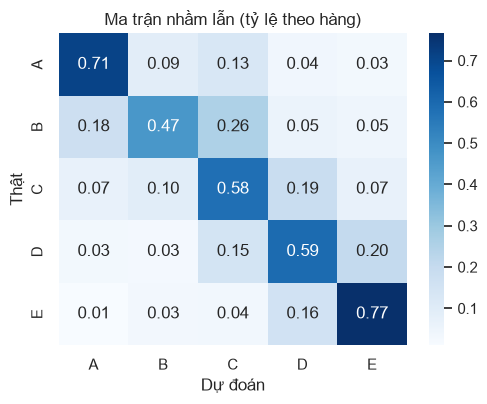

Dự đoán lệch tối đa 1 hạng: 89.4%


In [15]:
cm = confusion_matrix(y_dev, pred, labels=GRADES, normalize="true")
plt.figure(figsize=(5.2, 4.2))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=[g.upper() for g in GRADES],
            yticklabels=[g.upper() for g in GRADES])
plt.xlabel("Dự đoán"); plt.ylabel("Thật"); plt.title("Ma trận nhầm lẫn (tỷ lệ theo hàng)")
plt.tight_layout(); plt.savefig(FIG_DIR / "model_02_ma_tran_nham_lan.png", dpi=110); plt.show()
print("Dự đoán lệch tối đa 1 hạng:", f"{metrics(y_dev, pred)['within_one']:.1%}")

- Sai chủ yếu nằm **cạnh đường chéo** (B ↔ C, C ↔ D): mô hình hiểu thứ tự các hạng dù không được dạy trực tiếp.
- **B khó nhất**: ít mẫu nhất và nằm "kẹp" giữa A và C. A và E dễ nhất.

## 8.2. Theo quốc gia, và khi gặp một thị trường chưa từng thấy

In [16]:
has = lambda tag: X_dev["countries_tags"].map(lambda t: t is not None and tag in t).to_numpy()
fr, us = has("en:france"), has("en:united-states")
segments = {"Bán ở Pháp": fr, "Bán ở Mỹ": us, "Còn lại": ~fr & ~us}
pd.DataFrame({name: metrics(y_dev[m], pred[m], proba[m]) for name, m in segments.items()}).T[["macro_f1", "accuracy", "qwk"]] \
  .assign(so_dong=[int(m.sum()) for m in segments.values()])

,macro_f1,accuracy,qwk,so_dong
Bán ở Pháp,0.6498,0.6699,0.8130,6883
Bán ở Mỹ,0.6222,0.6472,0.7362,9005
Còn lại,0.6056,0.6172,0.7636,8132


In [17]:
# Giữ lại Pháp: học trên sản phẩm KHÔNG bán ở Pháp (và không cùng thương hiệu), đo trên sản phẩm bán ở Pháp
role = split_dev["country_holdout"].to_numpy()
model_fr = factories[best_name]().fit(X_dev[role == "train"], y_dev[role == "train"])
ev = role == "eval"
m = metrics(y_dev[ev], model_fr.predict(X_dev[ev]))
print(f"Học không có hàng Pháp ({(role == 'train').sum()} dòng) -> đo trên {ev.sum()} dòng Pháp: Macro-F1 {m['macro_f1']:.3f}")
print(f"So với khi được học cả hàng Pháp (8.2 ở trên): {metrics(y_dev[fr], pred[fr])['macro_f1']:.3f}")

Học không có hàng Pháp (13248 dòng) -> đo trên 6883 dòng Pháp: Macro-F1 0.596
So với khi được học cả hàng Pháp (8.2 ở trên): 0.650


Mô hình vẫn dùng được ở một thị trường chưa từng thấy, nhưng **tụt vài điểm**: mỗi nước có thói quen ghi thành phần, danh mục khác nhau. Khi áp dụng cho thị trường mới (ví dụ Việt Nam) cần thêm dữ liệu của thị trường đó.

## 8.3. Nhóm sản phẩm nào khó nhất? (câu hỏi nghiên cứu 1)

In [18]:
group = X_dev["pnns_groups_1"].fillna("missing").to_numpy()
rows = []
for g in pd.unique(group):
    m = group == g
    if m.sum() >= 200:
        rows.append({"nhóm pnns_groups_1": g, "số sản phẩm": int(m.sum()), **metrics(y_dev[m], pred[m])})
pd.DataFrame(rows).sort_values("macro_f1")[["nhóm pnns_groups_1", "số sản phẩm", "macro_f1", "accuracy", "within_one"]]

,nhóm pnns_groups_1,số sản phẩm,macro_f1,accuracy,within_one
0,composite foods,1620,0.4208,0.5420,0.8481
2,missing,4799,0.5069,0.5703,0.8343
3,sugary snacks,3951,0.5124,0.7846,0.9701
8,salty snacks,956,0.5142,0.5450,0.9215
9,fish meat eggs,2016,0.5321,0.6002,0.8656
6,fruits and vegetables,1305,0.5690,0.7364,0.9073
4,cereals and potatoes,2766,0.5886,0.6341,0.8977
5,fats and sauces,1620,0.5916,0.6031,0.8901
7,milk and dairy products,2409,0.6006,0.6671,0.9411
1,beverages,2476,0.6656,0.6648,0.8764


Nhóm khó nhất là **composite foods** (món ăn chế biến sẵn trộn nhiều nguyên liệu, Macro-F1 khoảng 0,42), sản phẩm **thiếu nhóm** ("missing") và snack mặn: hạng của chúng phụ thuộc vào *lượng* từng nguyên liệu (bao nhiêu thịt, phô mai, dầu, muối), thứ chỉ có trong bảng dinh dưỡng mà mô hình cố ý không được dùng. Nhóm sugary snacks có Macro-F1 thấp nhưng accuracy cao (khoảng 78%): gần như toàn D/E và mô hình đoán đúng, chỉ vài sản phẩm A/B hiếm trong nhóm bị sai nên Macro-F1 trong nhóm bị kéo xuống. Đồ uống lại dễ nhất (khoảng 0,67): đồ uống có đường hay không có đường quyết định gần hết hạng.

## 8.4. Nhóm đặc trưng nào quan trọng? (ablation, câu hỏi nghiên cứu 3)
Bỏ lần lượt từng nhóm đặc trưng, đánh giá chéo lại với tham số tốt nhất. Macro-F1 giảm càng nhiều, nhóm càng quan trọng. Thêm hai cấu hình để đo riêng **NOVA bổ sung bao nhiêu so với riêng thành phần**.

In [19]:
full = results[best_name]["macro_f1"].mean()
rows = []
configs = {f"bỏ {g}": [x for x in GROUPS if x != g] for g in GROUPS}
configs["chỉ thành phần (ingredients + position)"] = ["ingredients", "position"]
configs["thành phần + NOVA"] = ["ingredients", "position", "nova"]
start = time.time()
for name, groups in configs.items():
    f1 = cross_validate(lambda: make_model("lgbm", groups=groups, **best_params), X_dev, y_dev, folds)[0]["macro_f1"].mean()
    rows.append({"cấu hình": name, "Macro-F1": round(f1, 3), "thay đổi so với đủ nhóm": round(f1 - full, 3)})
print(f"{(time.time() - start) / 60:.1f} phút")
ablation = pd.DataFrame(rows).sort_values("thay đổi so với đủ nhóm")
ablation

11.3 phút


,cấu hình,Macro-F1,thay đổi so với đủ nhóm
8,chỉ thành phần (ingredients + position),0.557,-0.068
9,thành phần + NOVA,0.559,-0.066
4,bỏ categories,0.566,-0.058
2,bỏ ingredients,0.593,-0.032
1,bỏ position,0.619,-0.006
6,bỏ labels,0.622,-0.003
3,bỏ additives,0.623,-0.002
0,bỏ numeric,0.624,-0.001
5,bỏ nova,0.624,-0.001
7,bỏ countries,0.624,-0.000


- **Danh mục quan trọng nhất**: bỏ đi thì Macro-F1 tụt mạnh nhất (khoảng 0,06). Loại sản phẩm quyết định khoảng hạng (nước uống khác bánh quy).
- **Thành phần** đứng thứ hai (khoảng 0,03): trong cùng danh mục, thành phần phân biệt sản phẩm tốt và kém.
- Các nhóm còn lại (vị trí, nhãn, phụ gia, số đếm, NOVA, quốc gia) mỗi nhóm chỉ góp ≤ 0,006 khi đã có danh mục và thành phần, vì thông tin của chúng **trùng lặp** (ví dụ phụ gia đã nằm trong danh sách thành phần).
- **NOVA:** "thành phần + NOVA" chỉ hơn "chỉ thành phần" khoảng 0,002, nhỏ hơn độ lệch giữa các fold. NOVA được Open Food Facts tính từ chính thành phần và phụ gia, nên mô hình đã có thông tin đó từ thành phần; NOVA hầu như không bổ sung gì.

## 8.5. Thành phần, phụ gia nào kéo hạng xuống D/E? (câu hỏi nghiên cứu 2)
Học mô hình tốt nhất trên toàn bộ dev, rồi:
1. **Độ quan trọng (gain):** đặc trưng nào giúp các cây giảm lỗi nhiều nhất.
2. **Hướng tác động:** với từng thẻ thành phần/phụ gia quan trọng, so xác suất dự đoán D hoặc E (ngoài fold) giữa sản phẩm có thẻ và không có thẻ.

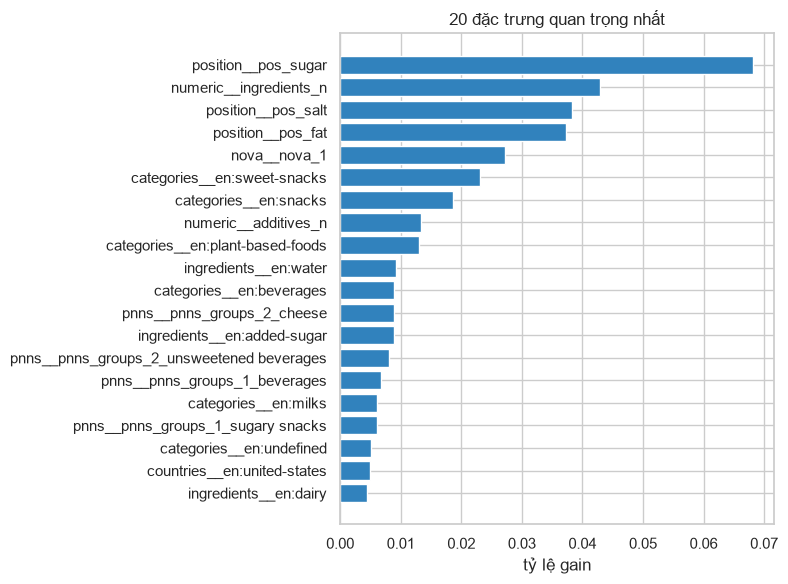

,ingredients,categories,position,pnns,numeric,nova,labels,additives,analysis,countries,first
tỷ lệ gain theo phần,0.337,0.221,0.144,0.085,0.061,0.034,0.027,0.025,0.024,0.022,0.02


In [20]:
final_model = factories[best_name]().fit(X_dev, y_dev)
names = np.array(feature_names(final_model["features"]))
clf = final_model["model"]
gain = clf.booster_.feature_importance("gain") if hasattr(clf, "booster_") else clf.feature_importances_
importance = pd.Series(gain / gain.sum(), index=names).sort_values(ascending=False)

top = importance.head(20)[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top.index, top.values, color="#3182bd")
plt.xlabel("tỷ lệ gain"); plt.title("20 đặc trưng quan trọng nhất")
plt.tight_layout(); plt.savefig(FIG_DIR / "model_03_dac_trung_quan_trong.png", dpi=110); plt.show()

by_group = pd.Series(importance.values, index=[n.split("__")[0] for n in importance.index]).groupby(level=0).sum()
by_group.sort_values(ascending=False).round(3).to_frame("tỷ lệ gain theo phần").T

In [21]:
M = final_model["features"].transform(X_dev).tocsc()
p_de = proba[:, GRADES.index("d")] + proba[:, GRADES.index("e")]
rows = []
for name in importance.index:
    if name.startswith(("ingredients__", "additives__")) and len(rows) < 40:
        has_tag = M[:, list(names).index(name)].toarray().ravel() > 0
        rows.append({"thẻ": name.split("__")[1], "loại": name.split("__")[0], "số sản phẩm": int(has_tag.sum()),
                     "P(D/E) khi có": p_de[has_tag].mean(), "P(D/E) khi không": p_de[~has_tag].mean()})
effect = pd.DataFrame(rows)
effect["chênh"] = effect["P(D/E) khi có"] - effect["P(D/E) khi không"]
effect.sort_values("chênh", ascending=False).head(12).round(3)

,thẻ,loại,số sản phẩm,P(D/E) khi có,P(D/E) khi không,chênh
38,en:cocoa-butter,ingredients,1790,0.943,0.477,0.466
3,en:cocoa,ingredients,2743,0.898,0.462,0.437
1,en:added-sugar,ingredients,12297,0.683,0.331,0.351
27,en:coconut-oil,ingredients,660,0.850,0.502,0.348
4,en:disaccharide,ingredients,11088,0.687,0.360,0.327
5,en:sugar,ingredients,10524,0.688,0.373,0.315
31,en:plant,ingredients,4317,0.754,0.459,0.295
2,en:dairy,ingredients,7201,0.681,0.439,0.243
22,en:pork,ingredients,1213,0.740,0.500,0.240
18,en:flavouring,ingredients,8613,0.655,0.431,0.223


In [22]:
effect.sort_values("chênh").head(8).round(3)       # các thẻ kéo hạng LÊN (giảm khả năng D/E)

,thẻ,loại,số sản phẩm,P(D/E) khi có,P(D/E) khi không,chênh
26,en:carrot,ingredients,1251,0.263,0.526,-0.263
10,en:tomato,ingredients,1958,0.321,0.529,-0.207
20,en:sweetener,ingredients,419,0.319,0.515,-0.196
15,en:onion,ingredients,2895,0.394,0.528,-0.134
12,en:legume,ingredients,2229,0.406,0.523,-0.117
11,en:vegetable,ingredients,8032,0.449,0.543,-0.094
0,en:water,ingredients,9013,0.460,0.543,-0.082
33,en:tuber,ingredients,1040,0.449,0.515,-0.066


Kết luận câu hỏi 2: **bơ ca cao và ca cao, đường thêm vào, dầu dừa, sữa/bơ sữa, thịt heo (đồ nguội), hương liệu, các loại hạt và dầu mỡ** là những thẻ mà sản phẩm có chúng bị dự đoán D/E nhiều hơn hẳn (chênh 0,2-0,47 xác suất). Ngược lại **cà rốt, cà chua, chất tạo ngọt (đồ uống không đường), hành, đậu, rau, nước** kéo hạng lên. Phụ gia có lift cao ở EDA (phẩm màu, chất nhũ hóa) không nằm trong nhóm quan trọng nhất của mô hình: bỏ cả nhóm phụ gia chỉ giảm 0,002, nên phụ gia chủ yếu **đi cùng** bánh kẹo chứ không tự quyết định hạng. Đây là liên hệ, không phải nhân quả. Notebook 06 (mục 8.15) kiểm tra lại trên tập test bằng cách "tắt thẻ" và giải thích từng sản phẩm.

## 8.6. Lưu mô hình và dự đoán ngoài fold
- `artifacts/best_model.joblib`: mô hình tốt nhất (Pipeline đặc trưng + bộ phân loại) đã học trên **toàn bộ dev**, kèm tham số và kết quả đánh giá chéo. Dùng ở notebook 06 (đánh giá cuối) và dashboard. Mô hình này có **1.009 đặc trưng**, nhiều hơn con số 908 ở notebook 04: ngưỡng "thẻ có ở ≥ 100 sản phẩm" được đếm trên dữ liệu học, mà toàn bộ dev (23.922 dòng) nhiều hơn phần học của fold 0 (19.139 dòng), nên thêm khoảng 100 thẻ đạt ngưỡng. Mỗi fold ở trên cũng có số cột hơi khác nhau vì lý do này.
- `data/processed/oof_predictions.parquet`: dự đoán ngoài fold trên dev, để phân tích lỗi.
- `reports/model_results.json`: bảng so sánh, tham số, ablation.

In [23]:
import json, joblib, sklearn, lightgbm
from pathlib import Path

Path("artifacts").mkdir(exist_ok=True)
joblib.dump({"model": final_model, "name": best_name, "params": best_params if "Optuna" in best_name else None,
             "trained_on": f"dev ({len(X_dev)} dòng); tập test chưa mở",
             "cv_dev": results[best_name].mean().round(4).to_dict(),
             "versions": {"scikit-learn": sklearn.__version__, "lightgbm": lightgbm.__version__,
                          "pandas": pd.__version__, "python": sys.version.split()[0]}},
            "artifacts/best_model.joblib")

pred_df = pd.DataFrame({"row_id": X_dev["row_id"], "code": X_dev["code"], "fold": folds, "y_true": y_dev, "y_pred": pred})
for i, g in enumerate(GRADES):
    pred_df[f"p_{g}"] = proba[:, i]
pred_df.to_parquet("data/processed/oof_predictions.parquet", index=False)

summary = {"best_model": best_name, "best_params": best_params,
           "comparison": {n: {"mean": r.mean().round(4).to_dict(), "std": r.std().round(4).to_dict()} for n, r in results.items()},
           "ablation": ablation.to_dict(orient="records")}
Path("reports/model_results.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")

# Kiểm tra tệp mô hình mở lại được và dự đoán giống hệt
loaded = joblib.load("artifacts/best_model.joblib")["model"]
print("Nạp lại, dự đoán giống hệt:", (loaded.predict(X_dev.head(500)) == final_model.predict(X_dev.head(500))).all())

Nạp lại, dự đoán giống hệt: True


## Kết luận (so với tiêu chí thành công ở notebook 01)

| Tiêu chí | Kết quả trên dev |
|---|---|
| Vượt đường cơ sở `pnns_groups_2` trên cả Macro-F1 và QWK | **Đạt** (xem 7.7) |
| ≥ 85% dự đoán lệch tối đa 1 hạng | **Đạt** (xem 8.1) |
| Không dùng dinh dưỡng / thẻ lộ đáp án | **Đạt** (kiểm tra ở notebook 04: theo tên cột và theo giá trị) |
| Kết quả khách quan trên tập test | Không đo ở đây: tập test chỉ mở một lần ở **notebook 06**, sau khi đã chốt mô hình trong notebook này |

Hạn chế: Macro-F1 sau tinh chỉnh hơi lạc quan (tham số chọn trên chính 5 fold); mô hình không biết *lượng* đường/muối nên khó phân biệt hạng kề nhau (B/C, C/D); dữ liệu nghiêng về Mỹ và Pháp.